In [1]:
from astropy.io import fits
import numpy as np

h = fits.open("data/raw/full/ecliptic-virgo/2025W20_2D_0234_1_D3.fits")
h.info()


Filename: data/raw/full/ecliptic-virgo/2025W20_2D_0234_1_D3.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       239   (2040, 2040)   float32   
  2  FLAGS         1 ImageHDU       146   (2040, 2040)   int32   
  3  VARIANCE      1 ImageHDU       119   (2040, 2040)   float32   
  4  ZODI          1 ImageHDU       119   (2040, 2040)   float32   
  5  PSF           1 ImageHDU       509   (101, 101, 121)   float32   
  6  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [9J, 14J, 252E]   


In [2]:
img = h["IMAGE"]

print("Shape:          ", img.data.shape)
print("Unit:           ", img.header["BUNIT"])
print("Median value:   ", np.nanmedian(img.data))
print("Dead pixels:    ", np.isnan(img.data).sum())
print("Min / Max:      ", np.nanmin(img.data), "/", np.nanmax(img.data))

Shape:           (2040, 2040)
Unit:            MJy / sr
Median value:    0.21658063
Dead pixels:     217
Min / Max:       -957.5747 / 2915.9248


In [3]:
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord

w = WCS(img.header)
target = SkyCoord(180, 0, unit="deg")

x, y = w.world_to_pixel(target)
print("Our target (RA 180, Dec 0) is at pixel  x =", round(float(x), 1), " y =", round(float(y), 1))

Our target (RA 180, Dec 0) is at pixel  x = 691.7  y = 1408.0


In [4]:
from astropy.nddata import Cutout2D
import astropy.units as u

cut = Cutout2D(img.data, target, 1*u.deg, wcs=w)

print("Crop size (pixels):            ", cut.data.shape)
print("Bottom-left corner in full photo:", cut.origin_original)

Crop size (pixels):             (585, 585)
Bottom-left corner in full photo: (400, 1116)


In [5]:
flags = h["FLAGS"].data[cut.slices_original]
var   = h["VARIANCE"].data[cut.slices_original]
zodi  = h["ZODI"].data[cut.slices_original]

print("FLAGS:   ", flags.shape)
print("VARIANCE:", var.shape)
print("ZODI:    ", zodi.shape)

FLAGS:    (585, 585)
VARIANCE: (585, 585)
ZODI:     (585, 585)


In [6]:
print("Crop pixel (100, 200)       ->", cut.wcs.pixel_to_world(100, 200))
print("Full-photo pixel (500, 1316) ->", w.pixel_to_world(100 + 400, 200 + 1116))

Crop pixel (100, 200)       -> <SkyCoord (ICRS): (ra, dec) in deg
    (179.76799409, 0.28616134)>
Full-photo pixel (500, 1316) -> <SkyCoord (ICRS): (ra, dec) in deg
    (179.76799409, 0.28616134)>


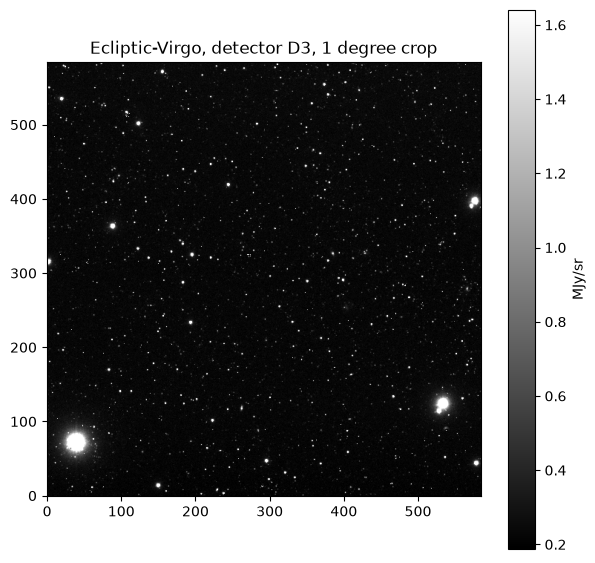

In [7]:
import matplotlib.pyplot as plt

lo, hi = np.nanpercentile(cut.data, [1, 99.5])

plt.figure(figsize=(7, 7))
plt.imshow(cut.data, origin="lower", cmap="gray", vmin=lo, vmax=hi)
plt.title("Ecliptic-Virgo, detector D3, 1 degree crop")
plt.colorbar(label="MJy/sr")
plt.show()

In [8]:
ww = WCS(img.header, fobj=h, key="W")
ww.sip = None

wl, bw = ww.pixel_to_world_values(500, 1316)
print("This pixel sees light at", round(float(wl), 3), "microns, band width", round(float(bw), 3), "microns")

INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]
This pixel sees ligh

In [9]:
x0, y0 = cut.origin_original   # where our square starts in the full photo: (400, 1116)

def crop_header(header):
    hdr = header.copy()
    hdr.update(cut.wcs.to_header(relax=True))       # 1. sky map: use Cutout2D's corrected map
    for key in ("CRPIX1A", "CRPIX1W"):              # 2. detector + wavelength maps: shift x
        if key in hdr:
            hdr[key] = hdr[key] - x0
    for key in ("CRPIX2A", "CRPIX2W"):              #    ...and shift y
        if key in hdr:
            hdr[key] = hdr[key] - y0
    hdr["CROP_X0"] = (int(x0), "crop origin x in original photo (0-based)")   # 3. record where we cut
    hdr["CROP_Y0"] = (int(y0), "crop origin y in original photo (0-based)")
    return hdr

print("Crop starts at x0 =", x0, " y0 =", y0)

Crop starts at x0 = 400  y0 = 1116


In [10]:
import os

out = fits.HDUList([fits.PrimaryHDU(header=h[0].header)])          # layer 0: general info
for name in ("IMAGE", "FLAGS", "VARIANCE", "ZODI"):                  # layers 1-4: cropped
    data = h[name].data[cut.slices_original]
    out.append(fits.ImageHDU(data, header=crop_header(h[name].header), name=name))
out.append(h["PSF"].copy())                                          # layer 5: kept whole
out.append(h["WCS-WAVE"].copy())                                     # layer 6: kept whole

os.makedirs("data/lesson", exist_ok=True)
out.writeto("data/lesson/virgo_D3_crop.fits", overwrite=True)
print("Saved:", round(os.path.getsize("data/lesson/virgo_D3_crop.fits") / 1e6, 1), "MB")

Saved: 10.5 MB


In [11]:
c = fits.open("data/lesson/virgo_D3_crop.fits")
c.info()
ci = c["IMAGE"]

print("\n1) SKY map")
print("   crop pixel (100,200):", WCS(ci.header).pixel_to_world(100, 200))
print("   original (500,1316): ", w.pixel_to_world(500, 1316))

print("\n2) Same pixel value?", ci.data[200, 100] == img.data[1316, 500])

wa = WCS(ci.header, key="A"); wa.sip = None
print("\n3) DETECTOR map: crop pixel (100,200) is sensor pixel", wa.pixel_to_world_values(100, 200))

wwc = WCS(ci.header, fobj=c, key="W"); wwc.sip = None
print("\n4) WAVELENGTH map: crop pixel (100,200) sees", round(float(wwc.pixel_to_world_values(100, 200)[0]), 3), "microns")
print("   original pixel (500,1316) sees           ", round(float(ww.pixel_to_world_values(500, 1316)[0]), 3), "microns")

Filename: data/lesson/virgo_D3_crop.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       241   (585, 585)   float32   
  2  FLAGS         1 ImageHDU       148   (585, 585)   int32   
  3  VARIANCE      1 ImageHDU       121   (585, 585)   float32   
  4  ZODI          1 ImageHDU       121   (585, 585)   float32   
  5  PSF           1 ImageHDU       509   (101, 101, 121)   float32   
  6  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [9J, 14J, 252E]   

1) SKY map
   crop pixel (100,200): <SkyCoord (ICRS): (ra, dec) in deg
    (179.76799409, 0.28616134)>
   original (500,1316):  <SkyCoord (ICRS): (ra, dec) in deg
    (179.76799409, 0.28616134)>

2) Same pixel value? True
INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astr

In [2]:
!python crop_spherex.py

Photos: 1401 | already cropped: 1401 | missing originals: 0 | to crop now: 0 | workers: 4

Done in 0.0 min: 0 cropped OK, 0 need checking, 0 failed, 1401 skipped (already done).
Details per photo: crop_log.csv


In [3]:
import csv
from collections import Counter, defaultdict

rows = list(csv.DictReader(open("crop_log.csv", encoding="utf-8")))
status = Counter(r["status"] for r in rows)
print("Status:", dict(status))

per = defaultdict(lambda: {"n": 0, "mb": 0.0, "edge": 0, "min_cov": 1.0})
for r in rows:
    if r["status"] == "ok":
        d = per[r["patch"]]
        d["n"] += 1
        d["mb"] += float(r["mb"])
        cov = float(r["coverage"])
        d["edge"] += cov < 0.9999
        d["min_cov"] = min(d["min_cov"], cov)

print(f"\n{'patch':15} {'crops':>6} {'GB':>6} {'at edge':>8} {'min coverage':>13}")
for p, d in sorted(per.items()):
    print(f"{p:15} {d['n']:6d} {d['mb']/1000:6.2f} {d['edge']:8d} {d['min_cov']:13.0%}")
print("\nTotal crops:", sum(d["n"] for d in per.values()))

Status: {'ok': 1401}

patch            crops     GB  at edge  min coverage
3i-atlas           259   1.82       46           24%
ceres              277   1.78       71           51%
ecliptic-ra90      218   2.30       66           53%
ecliptic-virgo     341   3.59      109           53%
nep-cats-eye       306   1.74        0          100%

Total crops: 1401


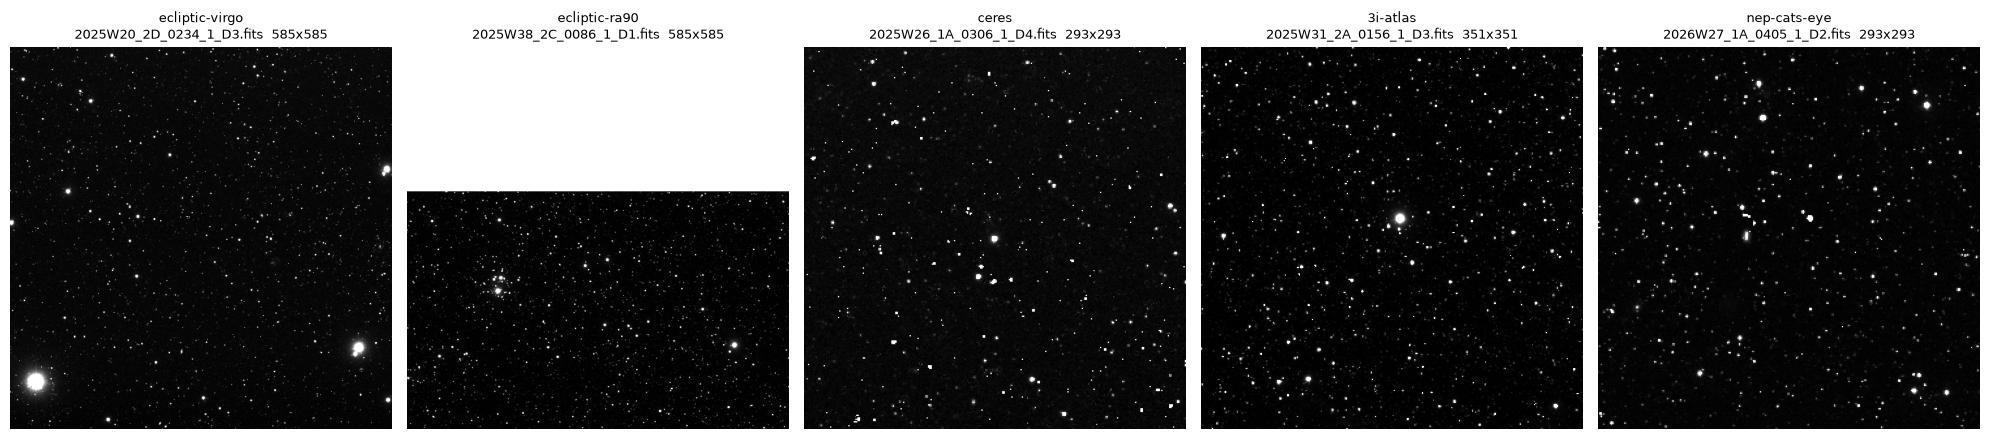

In [4]:
import glob, os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

patches = ["ecliptic-virgo", "ecliptic-ra90", "ceres", "3i-atlas", "nep-cats-eye"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, p in zip(axes, patches):
    f = sorted(glob.glob(f"data/cut/{p}/*.fits"))[0]
    d = fits.getdata(f, "IMAGE")
    lo, hi = np.nanpercentile(d, [1, 99.5])
    ax.imshow(d, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(f"{p}\n{os.path.basename(f)}  {d.shape[1]}x{d.shape[0]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [7]:
!python clean_spherex.py --limit 3

Photos: 15 | already cleaned: 15 | missing crops: 0 | to clean now: 0 | workers: 4

Done in 0.0 min: 0 cleaned OK, 0 failed, 15 skipped (already done).
(values are medians per patch)  Details per photo: clean_log.csv


In [8]:
!python clean_spherex.py

Photos: 1401 | already cleaned: 1401 | missing crops: 0 | to clean now: 0 | workers: 4

Done in 0.0 min: 0 cleaned OK, 0 failed, 1401 skipped (already done).
(values are medians per patch)  Details per photo: clean_log.csv


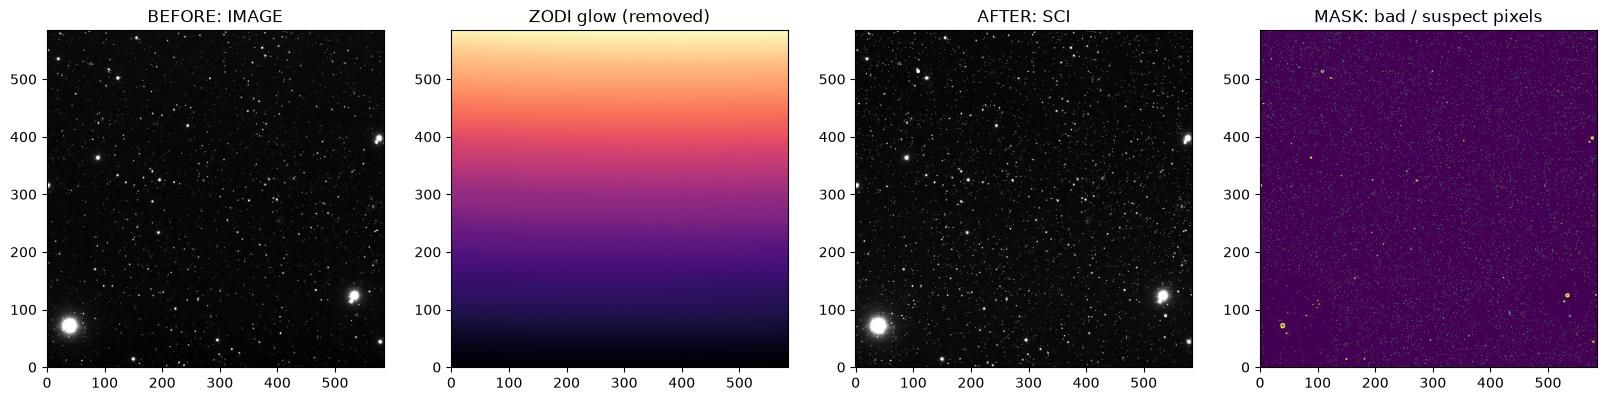

Layers in the clean file: ['PRIMARY', 'SCI', 'ERR', 'SNR', 'MASK', 'FLAGS', 'ZODI', 'PSF', 'WCS-WAVE']
Glow removed (median): 0.194327 MJy/sr
Bad pixels: 0.463 %  | suspect (kept): 2.707 %


In [9]:
import numpy as np, matplotlib.pyplot as plt
from astropy.io import fits

name = "ecliptic-virgo/2025W20_2D_0234_1_D3.fits"
a = fits.open("data/cut/" + name)      # before
b = fits.open("data/clean/" + name)    # after

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
d = a["IMAGE"].data; lo, hi = np.nanpercentile(d, [1, 99.5])
ax[0].imshow(d, origin="lower", cmap="gray", vmin=lo, vmax=hi); ax[0].set_title("BEFORE: IMAGE")
ax[1].imshow(a["ZODI"].data, origin="lower", cmap="magma");      ax[1].set_title("ZODI glow (removed)")
s = b["SCI"].data; lo, hi = np.nanpercentile(s, [1, 99.5])
ax[2].imshow(s, origin="lower", cmap="gray", vmin=lo, vmax=hi); ax[2].set_title("AFTER: SCI")
ax[3].imshow(b["MASK"].data & 3, origin="lower", cmap="viridis"); ax[3].set_title("MASK: bad / suspect pixels")
plt.show()

print("Layers in the clean file:", [x.name for x in b])
print("Glow removed (median):", b["SCI"].header["ZODI_MED"], "MJy/sr")
print("Bad pixels:", b["SCI"].header["PCT_BAD"], "%  | suspect (kept):", b["SCI"].header["PCT_SUSP"], "%")

In [1]:
import os
for f in ["data/cut/ecliptic-virgo/2025W20_2D_0234_1_D3.fits", "data/clean/ecliptic-virgo/2025W20_2D_0234_1_D3.fits"]:
    if os.path.exists(f):
        os.remove(f); print("removed", f)

removed data/cut/ecliptic-virgo/2025W20_2D_0234_1_D3.fits
removed data/clean/ecliptic-virgo/2025W20_2D_0234_1_D3.fits


In [2]:
!python crop_spherex.py

Photos: 1401 | already cropped: 88 | missing originals: 0 | to crop now: 1313 | workers: 4
  [25/1313] ok     ecliptic-virgo 2025W51_2A_0242_1 D4  
  [50/1313] ok     ecliptic-virgo 2025W51_2A_0573_4 D4  
  [75/1313] ok     ecliptic-virgo 2025W52_1A_0223_1 D1  
  [100/1313] ok     ecliptic-virgo 2025W52_1A_0576_3 D2  
  [125/1313] ok     ecliptic-virgo 2025W52_2A_0337_3 D6  
  [150/1313] ok     ecliptic-virgo 2026W21_1A_0489_1 D2  
  [175/1313] ok     ecliptic-virgo 2026W22_2A_0027_2 D1  
  [200/1313] ok     ecliptic-virgo 2026W23_1A_0602_2 D4  
  [225/1313] ok     ecliptic-virgo 2026W25_1A_0551_2 D5  
  [250/1313] ok     ecliptic-virgo 2026W26_1A_0654_1 D2  
  [275/1313] ok     ceres          2025W26_1A_0618_3 D4  
  [300/1313] ok     ceres          2025W26_2A_0553_3 D5  
  [325/1313] ok     ceres          2025W27_1A_0145_3 D2  
  [350/1313] ok     ceres          2025W28_1B_0010_1 D5  
  [375/1313] ok     ceres          2025W28_1B_0548_3 D3  
  [400/1313] ok     ceres          2025W29

In [3]:
!python clean_spherex.py

Photos: 1401 | already cleaned: 0 | missing crops: 0 | to clean now: 1401 | workers: 4
  [100/1401] ok     ecliptic-virgo 2025W22_1B_0154_1 D1  
  [200/1401] ok     ecliptic-virgo 2025W52_2A_0007_3 D3  
  [300/1401] ok     ecliptic-virgo 2026W24_2B_0184_1 D5  
  [400/1401] ok     ceres          2025W27_1A_0105_1 D2  
  [500/1401] ok     ceres          2025W51_1A_0095_3 D2  
  [600/1401] ok     ceres          2025W52_1A_0684_2 D5  
  [700/1401] ok     3i-atlas       2025W32_2D_0355_2 D4  
  [800/1401] ok     3i-atlas       2025W50_1A_0038_3 D1  
  [900/1401] ok     ecliptic-ra90  2025W38_2C_0489_2 D5  
  [1000/1401] ok     ecliptic-ra90  2026W11_1A_0228_3 D6  
  [1100/1401] ok     nep-cats-eye   2026W27_2A_0075_1 D1  
  [1200/1401] ok     nep-cats-eye   2026W30_1B_0481_3 D2  
  [1300/1401] ok     nep-cats-eye   2026W33_1A_0146_3 D5  
  [1400/1401] ok     nep-cats-eye   2026W35_2A_0642_4 D3  
  [1401/1401] ok     nep-cats-eye   2026W35_2A_0642_4 D6  

Done in 7.1 min: 1401 cleaned OK, 0 

In [4]:
!python align_spherex.py

Photos: 1401 | already aligned: 0 | to align now: 1401 | workers: 4
  [100/1401] ok     ecliptic-virgo frame  100  
  [200/1401] ok     ecliptic-virgo frame  200  
  [300/1401] ok     ecliptic-virgo frame  301  
  [400/1401] ok     ceres          frame   58  
  [500/1401] ok     ceres          frame  160  
  [600/1401] ok     ceres          frame  260  
  [700/1401] ok     3i-atlas       frame   83  
  [800/1401] ok     3i-atlas       frame  182  
  [900/1401] ok     ecliptic-ra90  frame   23  
  [1000/1401] ok     ecliptic-ra90  frame  123  
  [1100/1401] ok     nep-cats-eye   frame    5  
  [1200/1401] ok     nep-cats-eye   frame  105  
  [1300/1401] ok     nep-cats-eye   frame  204  
  [1400/1401] ok     nep-cats-eye   frame  305  
  [1401/1401] ok     nep-cats-eye   frame  306  

Checking that stars line up and writing the time-ordered index...
  ecliptic-virgo   341 frames    1 grid(s)  2025-05-16 -> 2026-06-25   stars line up (shift <= 1 px): 336 / 336 checked
  ceres            

In [5]:
!python clean_spherex.py --redo

Photos: 1401 | already cleaned: 0 | missing crops: 0 | to clean now: 1401 | workers: 4
  [100/1401] ok     ecliptic-virgo 2025W21_2C_0468_3 D4  
  [200/1401] ok     ecliptic-virgo 2025W52_2A_0007_4 D6  
  [300/1401] ok     ecliptic-virgo 2026W24_2B_0171_4 D4  
  [400/1401] ok     ceres          2025W27_1A_0105_1 D2  
  [500/1401] ok     ceres          2025W51_1A_0095_3 D2  
  [600/1401] ok     ceres          2026W01_1A_0203_1 D2  
  [700/1401] ok     3i-atlas       2025W32_2D_0355_3 D1  
  [800/1401] ok     3i-atlas       2025W50_1A_0038_2 D4  
  [900/1401] ok     ecliptic-ra90  2025W38_2C_0489_2 D5  
  [1000/1401] ok     ecliptic-ra90  2026W11_1A_0228_3 D3  
  [1100/1401] ok     nep-cats-eye   2026W27_2A_0075_1 D1  
  [1200/1401] ok     nep-cats-eye   2026W30_1B_0481_3 D2  
  [1300/1401] ok     nep-cats-eye   2026W33_1A_0146_3 D5  
  [1400/1401] ok     nep-cats-eye   2026W35_2A_0642_4 D3  
  [1401/1401] ok     nep-cats-eye   2026W35_2A_0642_4 D6  

Done in 7.3 min: 1401 cleaned OK, 0 

In [6]:
!python align_spherex.py --redo

Photos: 1401 | already aligned: 0 | to align now: 1401 | workers: 4
  [100/1401] ok     ecliptic-virgo frame  100  
  [200/1401] ok     ecliptic-virgo frame  200  
  [300/1401] ok     ecliptic-virgo frame  301  
  [400/1401] ok     ceres          frame   60  
  [500/1401] ok     ceres          frame  159  
  [600/1401] ok     ceres          frame  259  
  [700/1401] ok     3i-atlas       frame   82  
  [800/1401] ok     3i-atlas       frame  182  
  [900/1401] ok     ecliptic-ra90  frame   23  
  [1000/1401] ok     ecliptic-ra90  frame  122  
  [1100/1401] ok     nep-cats-eye   frame    7  
  [1200/1401] ok     nep-cats-eye   frame  107  
  [1300/1401] ok     nep-cats-eye   frame  205  
  [1400/1401] ok     nep-cats-eye   frame  305  
  [1401/1401] ok     nep-cats-eye   frame  306  

Checking that stars line up and writing the time-ordered index...
  ecliptic-virgo   341 frames    1 grid(s)  2025-05-16 -> 2026-06-25   stars line up (shift <= 1 px): 336 / 336 checked
  ceres            

In [7]:
!python diff_spherex.py


ecliptic-virgo: 341 frames
  D1:  55 frames -> static sky written | star pixels cancelled (|S/N| < 5): 81.2% | leftovers per frame (median): 18
  D2:  59 frames -> static sky written | star pixels cancelled (|S/N| < 5): 81.0% | leftovers per frame (median): 28
  D3:  57 frames -> static sky written | star pixels cancelled (|S/N| < 5): 82.1% | leftovers per frame (median): 32
  D4:  55 frames -> static sky written | star pixels cancelled (|S/N| < 5): 84.6% | leftovers per frame (median): 130
  D5:  59 frames -> static sky written | star pixels cancelled (|S/N| < 5): 86.6% | leftovers per frame (median): 47
  D6:  56 frames -> static sky written | star pixels cancelled (|S/N| < 5): 87.1% | leftovers per frame (median): 101
  -> 341 difference images in data\diff\ecliptic-virgo

ecliptic-ra90: 218 frames
  D1:  36 frames -> static sky written | star pixels cancelled (|S/N| < 5): 78.7% | leftovers per frame (median): 112
  D2:  36 frames -> static sky written | star pixels cancelled (|S/N

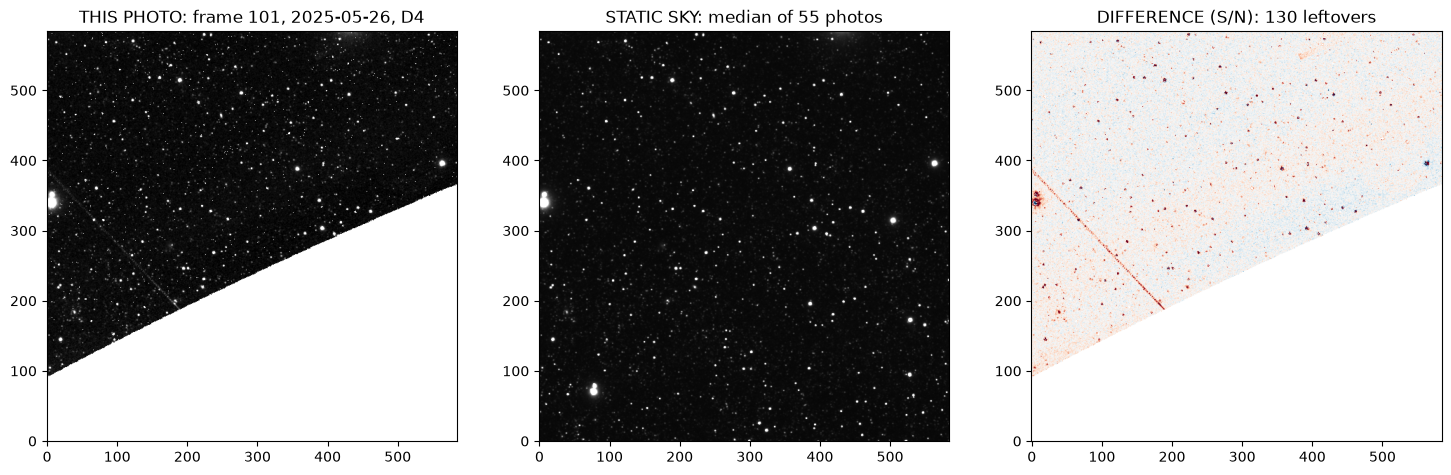

In [8]:
import numpy as np, matplotlib.pyplot as plt, csv
from astropy.io import fits

patch = "ecliptic-virgo"
rows = list(csv.DictReader(open(f"data/diff/{patch}/diff_frames.csv")))
r = rows[100]                                              # try other numbers too
a = fits.open(f"data/aligned/{patch}/{r['file']}")         # the photo
d = fits.open(f"data/diff/{patch}/{r['file']}")            # its difference image
s = fits.open(f"data/diff/{patch}/static_sky_{r['detector']}.fits")   # the static sky

img = a["SCI"].data - a["SCI"].header["BKG_MED"]
lo, hi = np.nanpercentile(img, [1, 99.5])
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
ax[0].set_title(f"THIS PHOTO: frame {r['frame']}, {r['t_mid_utc'][:10]}, {r['detector']}")
ax[1].imshow(s["STATIC"].data, origin="lower", cmap="gray", vmin=lo, vmax=hi)
ax[1].set_title(f"STATIC SKY: median of {s['STATIC'].header['NFRAMES']} photos")
ax[2].imshow(d["DIFF_SNR"].data, origin="lower", cmap="RdBu_r", vmin=-8, vmax=8)
ax[2].set_title(f"DIFFERENCE (S/N): {r['leftovers_snr5']} leftovers")
plt.show()

In [1]:
!python labels_spherex.py --plan



ecliptic-virgo: 341 frames in 64 groups (longest 6.5 min) | search box 1.20 x 1.20 deg around 180.0000 +0.0000
  g001_20250516T214731  5 frames  4.3 min
  g002_20250517T091335  8 frames  6.4 min
  g003_20250517T105134  8 frames  6.4 min
  g004_20250518T013126  8 frames  6.4 min
  g005_20250519T033715  8 frames  6.4 min
  ...

ecliptic-ra90: 218 frames in 38 groups (longest 6.5 min) | search box 1.31 x 1.20 deg around 90.0000 +23.4400
  g001_20250918T223631  8 frames  6.5 min
  g002_20250919T095553  2 frames  0.0 min
  g003_20250919T180736  2 frames  0.0 min
  g004_20250920T151720  8 frames  6.4 min
  g005_20250920T232811  8 frames  6.4 min
  ...

nep-cats-eye: 306 frames in 159 groups (longest 2.2 min) | search box 1.76 x 0.70 deg around 270.0000 +66.5600
  g001_20260701T060959  2 frames  0.0 min
  g002_20260702T032606  2 frames  2.1 min
  g003_20260702T211616  2 frames  0.0 min
  g004_20260703T070425  2 frames  0.0 min
  g005_20260703T214021  2 frames  0.0 min
  ...

Done in 0.0 min.

In [2]:
!python labels_spherex.py --patch ecliptic-ra90


ecliptic-ra90: 218 frames in 38 groups (longest 6.5 min) | search box 1.31 x 1.20 deg around 90.0000 +23.4400
  JPL Horizons: SPHEREx position at 38 times ...
  JPL sb_ident: 38 groups (0 cached, 38 to ask, ~30-180 s each, 2 at a time)
    [1/38] g001_20250918T223631  40 objects  (26 s since start)
    [2/38] g002_20250919T095553  39 objects  (26 s since start)
    [3/38] g003_20250919T180736  36 objects  (49 s since start)
    [4/38] g004_20250920T151720  32 objects  (50 s since start)
    [5/38] g005_20250920T232811  31 objects  (74 s since start)
    [6/38] g006_20250921T141110  28 objects  (91 s since start)
    [7/38] g007_20250922T062346  26 objects  (97 s since start)
    [8/38] g008_20250922T125955  26 objects  (115 s since start)
    [9/38] g009_20250922T193003  27 objects  (121 s since start)
    [10/38] g010_20250923T065051  31 objects  (138 s since start)
    [11/38] g011_20250923T082622  32 objects  (145 s since start)
    [12/38] g012_20250923T100304  32 objects  (161 s 

In [3]:
!python labels_spherex.py


ecliptic-virgo: 341 frames in 64 groups (longest 6.5 min) | search box 1.20 x 1.20 deg around 180.0000 +0.0000
  JPL Horizons: SPHEREx position at 64 times ...
  JPL sb_ident: 64 groups (0 cached, 64 to ask, ~30-180 s each, 2 at a time)
    [1/64] g002_20250517T091335  31 objects  (25 s since start)
    [2/64] g001_20250516T214731  31 objects  (25 s since start)
    [3/64] g003_20250517T105134  31 objects  (48 s since start)
    [4/64] g004_20250518T013126  32 objects  (53 s since start)
    [5/64] g005_20250519T033715  31 objects  (72 s since start)
    [6/64] g006_20250520T184349  26 objects  (81 s since start)
    [7/64] g007_20250522T000557  26 objects  (96 s since start)
    [8/64] g008_20250522T032145  26 objects  (104 s since start)
    [9/64] g009_20250522T045831  26 objects  (123 s since start)
    [10/64] g010_20250522T130837  25 objects  (139 s since start)
    [11/64] g011_20250522T144202  25 objects  (147 s since start)
    [12/64] g012_20250522T193632  25 objects  (169 s

In [4]:
!python labels_confirm.py

ecliptic-ra90: 4319 labels | seen 58 | confirmed 21
   V < 17   seen    6 -> confirmed    6 (100% kept)
   V 17-18  seen    7 -> confirmed    4 ( 57% kept)
   V 18-19  seen    6 -> confirmed    4 ( 67% kept)
   V 19-21  seen   39 -> confirmed    7 ( 18% kept)
ecliptic-virgo: 8586 labels | seen 214 | confirmed 152
   V < 17   seen   97 -> confirmed   94 ( 97% kept)
   V 17-18  seen   42 -> confirmed   36 ( 86% kept)
   V 18-19  seen   37 -> confirmed   17 ( 46% kept)
   V 19-21  seen   38 -> confirmed    5 ( 13% kept)
nep-cats-eye: 0 labels | seen 0 | confirmed 0
labels_all.csv: 12905 rows, columns now end with: file, seen_n_group, confirmed


In [5]:
!python package_handoff.py --dry

Leak guard ...
   ok: no answer-key file, no comet_ra/comet_dec column, no 3I/ATLAS label row
   aligned  ecliptic-virgo   342 files  3.70 GB
   aligned  ecliptic-ra90    219 files  2.36 GB
   aligned  nep-cats-eye     307 files  1.75 GB
   aligned  3i-atlas         260 files  1.84 GB
   aligned  ceres            278 files  1.80 GB
   diff     ecliptic-virgo   348 files  1.55 GB
   diff     ecliptic-ra90    225 files  1.00 GB
   diff     nep-cats-eye     313 files  0.36 GB
   tables: 17 files | docs: README.md, DATA_DICTIONARY.md (MISSING)
   total ~14.35 GB -> handoff\Specula_handoff_v0.5
   free disk here: 329.61 GB
Dry run: nothing written.


In [6]:
!python package_handoff.py

Leak guard ...
   ok: no answer-key file, no comet_ra/comet_dec column, no 3I/ATLAS label row
   aligned  ecliptic-virgo   342 files  3.70 GB
   aligned  ecliptic-ra90    219 files  2.36 GB
   aligned  nep-cats-eye     307 files  1.75 GB
   aligned  3i-atlas         260 files  1.84 GB
   aligned  ceres            278 files  1.80 GB
   diff     ecliptic-virgo   348 files  1.55 GB
   diff     ecliptic-ra90    225 files  1.00 GB
   diff     nep-cats-eye     313 files  0.36 GB
   tables: 17 files | docs: README.md, DATA_DICTIONARY.md (MISSING)
   total ~14.35 GB -> handoff\Specula_handoff_v0.5
   free disk here: 329.61 GB
      aligned_ecliptic-virgo.zip: 100/342 files
      aligned_ecliptic-virgo.zip: 200/342 files
      aligned_ecliptic-virgo.zip: 300/342 files
[1/8] aligned_ecliptic-virgo.zip  3.70 GB  (84 s)
      aligned_ecliptic-ra90.zip: 100/219 files
      aligned_ecliptic-ra90.zip: 200/219 files
[2/8] aligned_ecliptic-ra90.zip  2.36 GB  (51 s)
      aligned_nep-cats-eye.zip: 100/3

In [7]:
!python labels_confirm.py

ecliptic-ra90: 4319 labels | seen 58 | confirmed 21
   V < 17   seen    6 -> confirmed    6 (100% kept)
   V 17-18  seen    7 -> confirmed    4 ( 57% kept)
   V 18-19  seen    6 -> confirmed    4 ( 67% kept)
   V 19-21  seen   39 -> confirmed    7 ( 18% kept)
ecliptic-virgo: 8586 labels | seen 214 | confirmed 152
   V < 17   seen   97 -> confirmed   94 ( 97% kept)
   V 17-18  seen   42 -> confirmed   36 ( 86% kept)
   V 18-19  seen   37 -> confirmed   17 ( 46% kept)
   V 19-21  seen   38 -> confirmed    5 ( 13% kept)
nep-cats-eye: 0 labels | seen 0 | confirmed 0
labels_all.csv: 12905 rows, columns now end with: file, seen_n_group, confirmed


In [8]:
!python package_handoff.py

Leak guard ...
   ok: no answer-key file, no comet_ra/comet_dec column, no 3I/ATLAS label row
   aligned  ecliptic-virgo   342 files  3.70 GB
   aligned  ecliptic-ra90    219 files  2.36 GB
   aligned  nep-cats-eye     307 files  1.75 GB
   aligned  3i-atlas         260 files  1.84 GB
   aligned  ceres            278 files  1.80 GB
   diff     ecliptic-virgo   348 files  1.55 GB
   diff     ecliptic-ra90    225 files  1.00 GB
   diff     nep-cats-eye     313 files  0.36 GB
   tables: 18 files | docs: handoff_docs\README.md, handoff_docs\DATA_DICTIONARY.md, handoff_docs\CLAUDE.md, handoff_docs\verify_and_unzip.py
   total ~14.35 GB -> handoff\Specula_handoff_v0.5
   free disk here: 315.24 GB
[1/8] aligned_ecliptic-virgo.zip already done - skipped
[2/8] aligned_ecliptic-ra90.zip already done - skipped
[3/8] aligned_nep-cats-eye.zip already done - skipped
[4/8] aligned_3i-atlas.zip already done - skipped
[5/8] aligned_ceres.zip already done - skipped
[6/8] diff_ecliptic-virgo.zip already 

In [9]:
!python labels_moving.py --plan


ceres: 277 frames in 50 bursts (longest 6.5 min) | search box 0.50 deg (+0.1 margin) per burst
  g001_20250624T093005  7 frames  6.4 min  centre 13.7737 -5.7714
  g002_20250624T191758  8 frames  6.5 min  centre 13.8653 -5.7543
  g003_20250626T053114  8 frames  6.4 min  centre 14.1814 -5.6967
  g004_20250626T084804  8 frames  6.4 min  centre 14.2113 -5.6914
  g005_20250628T094204  8 frames  6.4 min  centre 14.6516 -5.6160
  ...

3i-atlas: 259 frames in 46 bursts (longest 6.5 min) | search box 0.60 deg (+0.1 margin) per burst
  g001_20250801T080420  8 frames  6.4 min  centre 252.6711 -17.5306
  g002_20250801T161241  6 frames  4.3 min  centre 252.5361 -17.6335
  g003_20250806T231843  4 frames  2.1 min  centre 248.7904 -16.9195
  g004_20250807T023650  8 frames  6.5 min  centre 248.8612 -17.0138
  g005_20250807T055522  8 frames  6.5 min  centre 248.5952 -17.1659
  ...

Done in 0.0 min. Next: python labels_confirm.py


In [10]:
!python labels_moving.py


ceres: 277 frames in 50 bursts (longest 6.5 min) | search box 0.50 deg (+0.1 margin) per burst
  JPL Horizons: SPHEREx position at 50 times ...
  JPL sb_ident: 50 bursts (0 cached, 50 to ask, ~30-180 s each, 2 at a time)
    [1/50] g002_20250624T191758  6 objects  (27 s since start)
    [2/50] g001_20250624T093005  6 objects  (30 s since start)
    [3/50] g004_20250626T084804  7 objects  (63 s since start)
    [4/50] g003_20250626T053114  7 objects  (66 s since start)
    [5/50] g006_20250628T224223  5 objects  (89 s since start)
    [6/50] g005_20250628T094204  4 objects  (113 s since start)
    [7/50] g007_20250629T065420  5 objects  (130 s since start)
    [8/50] g008_20250629T150304  4 objects  (142 s since start)
    [9/50] g009_20250630T121431  4 objects  (160 s since start)
    [10/50] g010_20250630T170644  4 objects  (169 s since start)
    [11/50] g011_20250703T021155  7 objects  (192 s since start)
    [12/50] g012_20250703T070610  7 objects  (211 s since start)
    [13/50] 

In [11]:
!python labels_confirm.py

3i-atlas: 2118 labels | positions only (seen not measured)
ceres: 973 labels | positions only (seen not measured)
ecliptic-ra90: 4319 labels | seen 58 | confirmed 21
   V < 17   seen    6 -> confirmed    6 (100% kept)
   V 17-18  seen    7 -> confirmed    4 ( 57% kept)
   V 18-19  seen    6 -> confirmed    4 ( 67% kept)
   V 19-21  seen   39 -> confirmed    7 ( 18% kept)
ecliptic-virgo: 8586 labels | seen 214 | confirmed 152
   V < 17   seen   97 -> confirmed   94 ( 97% kept)
   V 17-18  seen   42 -> confirmed   36 ( 86% kept)
   V 18-19  seen   37 -> confirmed   17 ( 46% kept)
   V 19-21  seen   38 -> confirmed    5 ( 13% kept)
nep-cats-eye: 0 labels | seen 0 | confirmed 0
labels_all.csv: 15996 rows, columns now end with: file, seen_n_group, confirmed


In [12]:
!python package_handoff.py

Leak guard ...
   ok: no answer-key file, no comet_ra/comet_dec column, no 3I/ATLAS label row
   ok: no 3i-atlas label follows the true comet (closest label 12.2 px from it)
   aligned  ecliptic-virgo   342 files  3.70 GB
   aligned  ecliptic-ra90    219 files  2.36 GB
   aligned  nep-cats-eye     307 files  1.75 GB
   aligned  3i-atlas         260 files  1.84 GB
   aligned  ceres            278 files  1.80 GB
   diff     ecliptic-virgo   348 files  1.55 GB
   diff     ecliptic-ra90    225 files  1.00 GB
   diff     nep-cats-eye     313 files  0.36 GB
   tables: 22 files | docs: handoff_docs\README.md, handoff_docs\DATA_DICTIONARY.md, handoff_docs\CLAUDE.md, handoff_docs\verify_and_unzip.py
   total ~14.35 GB -> handoff\Specula_handoff_v0.5
   free disk here: 315.23 GB
[1/8] aligned_ecliptic-virgo.zip already done - skipped
[2/8] aligned_ecliptic-ra90.zip already done - skipped
[3/8] aligned_nep-cats-eye.zip already done - skipped
[4/8] aligned_3i-atlas.zip already done - skipped
[5/8]

In [13]:
!python package_handoff.py

Leak guard ...
   ok: no answer-key file, no comet_ra/comet_dec column, no 3I/ATLAS label row
   ok: no 3i-atlas label follows the true comet (closest label 12.2 px from it)
   aligned  ecliptic-virgo   342 files  3.70 GB
   aligned  ecliptic-ra90    219 files  2.36 GB
   aligned  nep-cats-eye     307 files  1.75 GB
   aligned  3i-atlas         260 files  1.84 GB
   aligned  ceres            278 files  1.80 GB
   diff     ecliptic-virgo   348 files  1.55 GB
   diff     ecliptic-ra90    225 files  1.00 GB
   diff     nep-cats-eye     313 files  0.36 GB
   tables: 22 files | docs: handoff_docs\README.md, handoff_docs\DATA_DICTIONARY.md, handoff_docs\CLAUDE.md, handoff_docs\verify_and_unzip.py
   total ~14.35 GB -> handoff\Specula_handoff_v0.5
   free disk here: 315.23 GB
[1/8] aligned_ecliptic-virgo.zip already done - skipped
[2/8] aligned_ecliptic-ra90.zip already done - skipped
[3/8] aligned_nep-cats-eye.zip already done - skipped
[4/8] aligned_3i-atlas.zip already done - skipped
[5/8]

In [14]:
!python package_handoff.py

Leak guard ...
   ok: no answer-key file, no comet_ra/comet_dec column, no 3I/ATLAS label row
   ok: no 3i-atlas label follows the true comet (closest label 12.2 px from it)
   aligned  ecliptic-virgo   342 files  3.70 GB
   aligned  ecliptic-ra90    219 files  2.36 GB
   aligned  nep-cats-eye     307 files  1.75 GB
   aligned  3i-atlas         260 files  1.84 GB
   aligned  ceres            278 files  1.80 GB
   diff     ecliptic-virgo   348 files  1.55 GB
   diff     ecliptic-ra90    225 files  1.00 GB
   diff     nep-cats-eye     313 files  0.36 GB
   tables: 22 files | docs: handoff_docs\README.md, handoff_docs\DATA_DICTIONARY.md, handoff_docs\CLAUDE.md, handoff_docs\verify_and_unzip.py
   total ~14.35 GB -> handoff\Specula_handoff_v0.5
   free disk here: 315.23 GB
[1/8] aligned_ecliptic-virgo.zip already done - skipped
[2/8] aligned_ecliptic-ra90.zip already done - skipped
[3/8] aligned_nep-cats-eye.zip already done - skipped
[4/8] aligned_3i-atlas.zip already done - skipped
[5/8]